# CIFAR-10 with 500 images: robustness to a shifted test set
Kaggle setup: Settings -> Accelerator = GPU T4 x2, Internet = ON (needed to download CIFAR-10).
Run the cells from top to bottom. The model is tiny, so one T4 is used (the second GPU is not needed).

In [1]:
# 1. Imports and settings
import os, math, time, random
from collections import defaultdict
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "| gpus:", torch.cuda.device_count())

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
SMOKE = False                      # set True for a very fast test run (2 epochs, 1 seed)
SEEDS = [0] if SMOKE else [0, 1, 2]
EPOCHS = 2 if SMOKE else 60        # rule: maximum 60 epochs
BS = 64
OUT = "/kaggle/working/results"
os.makedirs(OUT, exist_ok=True)

device: cuda | gpus: 2


In [2]:
# 2. Data: 500 training images, 400/100 split, clean test
train_full = torchvision.datasets.CIFAR10(root="/kaggle/working/data", train=True, download=True)
clean_test = torchvision.datasets.CIFAR10(root="/kaggle/working/data", train=False, download=True)

# exactly the code from the assignment: 50 images per class, fixed seed
rng = np.random.default_rng(42)
targets = np.array(train_full.targets)
idx = np.concatenate([rng.choice(np.where(targets == c)[0], 50, replace=False) for c in range(10)])

X = torch.from_numpy(train_full.data[idx]).permute(0, 3, 1, 2).float() / 255   # images in [0,1]
y = torch.from_numpy(targets[idx]).long()

# stratified split: 40 train + 10 val per class
r2 = np.random.default_rng(0)
tr, va = [], []
for c in range(10):
    ci = np.where(y.numpy() == c)[0]
    r2.shuffle(ci)
    tr += list(ci[:40]); va += list(ci[40:])

Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]
Xte = torch.from_numpy(clean_test.data).permute(0, 3, 1, 2).float() / 255
yte = torch.tensor(clean_test.targets).long()
print("train", Xtr.shape, "val", Xva.shape, "clean test", Xte.shape)

100%|██████████| 170M/170M [38:46<00:00, 73.3kB/s] 


train torch.Size([400, 3, 32, 32]) val torch.Size([100, 3, 32, 32]) clean test torch.Size([10000, 3, 32, 32])


In [3]:
# 3. Helper functions for image transforms (used for the shifted test AND the training augmentation)
def U(n, lo, hi, g=None, d="cpu"):
    """n random numbers uniform in [lo, hi]"""
    return lo + (hi - lo) * torch.rand(n, generator=g, device=d)

def affine(x, angle_deg, scale, tx, ty, flip=None):
    """rotation + zoom + shift (+ horizontal flip) of a whole batch in one step"""
    B, d = x.size(0), x.device
    a = angle_deg * math.pi / 180
    c, s = torch.cos(a), torch.sin(a)
    inv = 1.0 / scale
    fx = torch.ones(B, device=d) if flip is None else flip
    th = torch.zeros(B, 2, 3, device=d)
    th[:, 0, 0] = c * inv * fx; th[:, 0, 1] = -s * inv; th[:, 0, 2] = tx
    th[:, 1, 0] = s * inv * fx; th[:, 1, 1] = c * inv;  th[:, 1, 2] = ty
    grid = F.affine_grid(th, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

def gblur(x, sigma=1.0, k=5):
    ax = torch.arange(k, dtype=torch.float32) - k // 2
    w = torch.exp(-ax ** 2 / (2 * sigma ** 2)); w = w / w.sum()
    ker = (w[:, None] * w[None, :]).to(x.device)[None, None].repeat(3, 1, 1, 1)
    return F.conv2d(F.pad(x, (k // 2,) * 4, mode="reflect"), ker, groups=3)

def gray(x):
    w = torch.tensor([0.299, 0.587, 0.114], device=x.device).view(1, 3, 1, 1)
    return (x * w).sum(1, keepdim=True)

def rect_mask(B, h, w, d, g=None, H=32):
    """mask with one random h x w rectangle (value 1) per image"""
    y0 = (torch.rand(B, generator=g, device=d) * (H - h + 1)).long()
    x0 = (torch.rand(B, generator=g, device=d) * (H - w + 1)).long()
    ys = torch.arange(H, device=d).view(1, H, 1)
    xs = torch.arange(H, device=d).view(1, 1, H)
    m = (ys >= y0.view(B, 1, 1)) & (ys < (y0 + h).view(B, 1, 1)) & \
        (xs >= x0.view(B, 1, 1)) & (xs < (x0 + w).view(B, 1, 1))
    return m.unsqueeze(1).float()

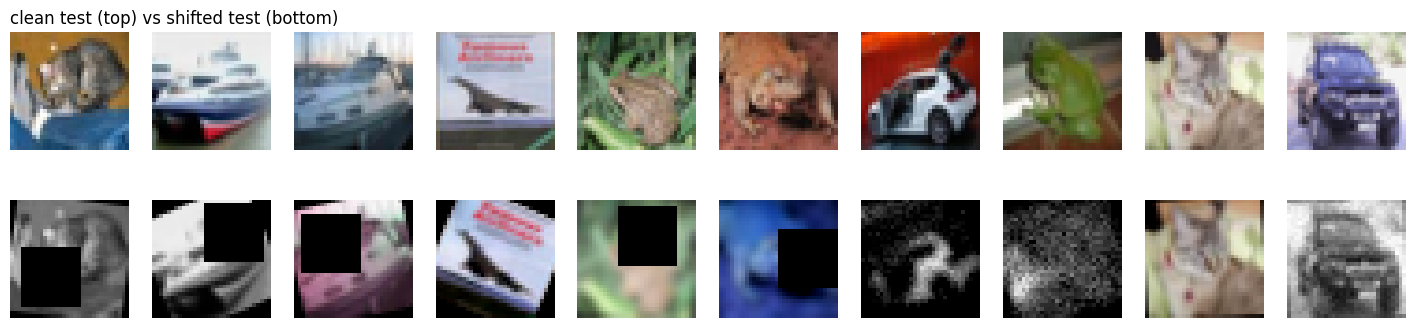

In [4]:
# 4. Build the shifted test set myself (fixed seed)
# listed corruptions: rotation +-25, brightness/contrast, blur, noise, 25% occlusion
# hidden corruption (my own choice): random grayscale OR random channel permutation
P_CORR = dict(rot=1.0, bc=0.8, blur=0.4, noise=0.4, occ=0.5, hidden=0.5)   # probability per image
ALL_OPS = ("rot", "bc", "blur", "noise", "occ", "hidden")

def corrupt(x, seed, ops=ALL_OPS, p_one=False):
    """p_one=True: apply the chosen corruption to EVERY image (used for per-corruption analysis)"""
    g = torch.Generator().manual_seed(seed)
    x = x.clone(); B = x.size(0)
    def on(name):
        p = 1.0 if p_one else P_CORR[name]
        return (torch.rand(B, generator=g) < p).view(B, 1, 1, 1).float()
    def blend(m, new, old):
        return m * new + (1 - m) * old
    if "rot" in ops:
        m = on("rot")
        x = blend(m, affine(x, U(B, -25, 25, g), torch.ones(B), torch.zeros(B), torch.zeros(B)), x)
    if "bc" in ops:
        m = on("bc"); c = U(B, 0.5, 1.5, g).view(B, 1, 1, 1); b = U(B, -0.25, 0.25, g).view(B, 1, 1, 1)
        mean = x.mean((1, 2, 3), keepdim=True)
        x = blend(m, (x - mean) * c + mean + b, x)
    if "blur" in ops:
        m = on("blur"); x = blend(m, gblur(x, 1.0), x)
    if "noise" in ops:
        m = on("noise"); s = U(B, 0.03, 0.12, g).view(B, 1, 1, 1)
        x = blend(m, x + torch.randn(x.shape, generator=g) * s, x)
    if "occ" in ops:                                   # 16x16 patch = 25% of the image
        m = on("occ"); hw = torch.full((B,), 16, dtype=torch.long)
        x = x * (1 - rect_mask(B, hw, hw, "cpu", g) * m)
    if "hidden" in ops:
        m = on("hidden")
        perms = torch.stack([torch.randperm(3, generator=g) for _ in range(B)])
        swapped = x.gather(1, perms.view(B, 3, 1, 1).expand(-1, -1, x.size(2), x.size(3)))
        use_gray = (torch.rand(B, generator=g) < 0.5).view(B, 1, 1, 1).float()
        x = blend(m, use_gray * gray(x).expand(-1, 3, -1, -1) + (1 - use_gray) * swapped, x)
    return x.clamp(0, 1)

Xva_s = corrupt(Xva, seed=1234, ops=("rot", "bc", "blur", "noise", "occ"))   # shifted VALIDATION (no hidden corruption)
shifted_test = corrupt(Xte, seed=2024)                                       # shifted TEST (all corruptions)

fig, ax = plt.subplots(2, 10, figsize=(18, 4))
for i in range(10):
    ax[0, i].imshow(Xte[i].permute(1, 2, 0)); ax[0, i].axis("off")
    ax[1, i].imshow(shifted_test[i].permute(1, 2, 0)); ax[1, i].axis("off")
ax[0, 0].set_title("clean test (top) vs shifted test (bottom)", loc="left")
plt.savefig(f"{OUT}/shifted_examples.png", dpi=120); plt.show()

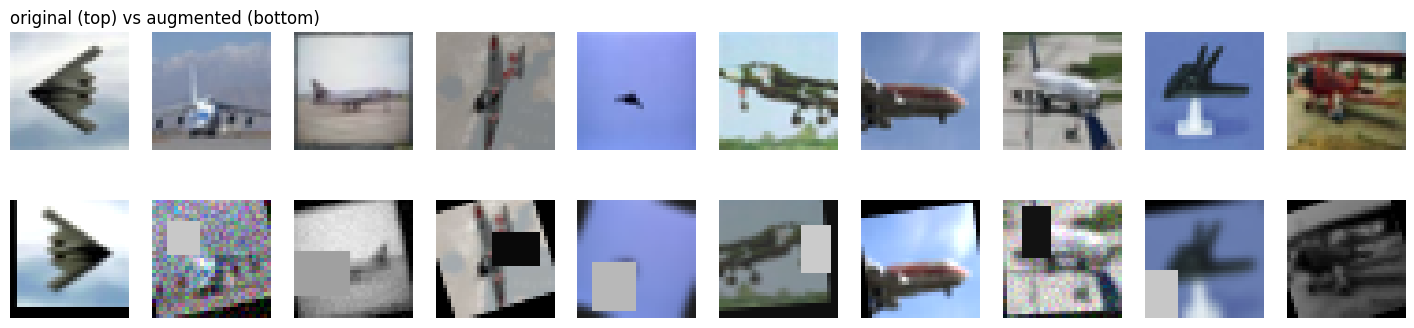

In [5]:
# 5. Training augmentation (on the fly, GPU, training batches only)
def augment(x, ysoft, cfg):
    B, d = x.size(0), x.device
    r = lambda lo, hi: U(B, lo, hi, None, d)
    pm = lambda p: (torch.rand(B, 1, 1, 1, device=d) < p).float()
    V = lambda t: t.view(B, 1, 1, 1)

    if cfg["geo"]:        # shift (crop with padding), rotation, scale, horizontal flip
        flip = 1 - 2 * (torch.rand(B, device=d) < 0.5).float()
        x = affine(x, r(-20, 20), r(0.9, 1.1), r(-0.25, 0.25), r(-0.25, 0.25), flip)

    if cfg["photo"]:      # contrast, brightness, saturation, blur, noise, random grayscale
        mean = x.mean((1, 2, 3), keepdim=True)
        m = pm(0.8)
        x = m * (((x - mean) * V(r(0.6, 1.4)) + mean) * V(r(0.6, 1.4))) + (1 - m) * x
        g_ = gray(x); x = g_ + (x - g_) * V(r(0.6, 1.4))
        m = pm(0.3); x = m * gblur(x, 1.0) + (1 - m) * x
        x = x + pm(0.3) * torch.randn_like(x) * V(r(0.02, 0.10))
        m = pm(0.15); x = m * gray(x).expand(-1, 3, -1, -1) + (1 - m) * x
        x = x.clamp(0, 1)

    if cfg["cutout"]:     # random erasing
        h = torch.randint(8, 17, (B,), device=d); w = torch.randint(8, 17, (B,), device=d)
        mask = rect_mask(B, h, w, d) * pm(0.5)
        x = x * (1 - mask) + mask * V(r(0, 1))

    if cfg["mix"]:        # MixUp or CutMix (50/50)
        perm = torch.randperm(B, device=d)
        if random.random() < 0.5:
            lam = float(np.random.beta(0.4, 0.4)); x = lam * x + (1 - lam) * x[perm]
        else:
            lam = float(np.random.beta(1.0, 1.0)); side = math.sqrt(1 - lam)
            h = w = int(round(32 * side)); cy, cx = random.randint(0, 31), random.randint(0, 31)
            y1, y2 = max(cy - h // 2, 0), min(cy + h // 2, 32)
            x1, x2 = max(cx - w // 2, 0), min(cx + w // 2, 32)
            x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
            lam = 1 - (y2 - y1) * (x2 - x1) / 1024
        ysoft = lam * ysoft + (1 - lam) * ysoft[perm]
    return x, ysoft

CFGS = {   # the rows of the ablation table
    "No augmentation":                  dict(geo=0, photo=0, cutout=0, mix=0, ls=0.0),
    "Geometric only":                   dict(geo=1, photo=0, cutout=0, mix=0, ls=0.0),
    "Photometric only":                 dict(geo=0, photo=1, cutout=0, mix=0, ls=0.0),
    "Geometric + photometric":          dict(geo=1, photo=1, cutout=0, mix=0, ls=0.0),
    "+ Cutout / Random Erasing":        dict(geo=1, photo=1, cutout=1, mix=0, ls=0.0),
    "+ Mixup/CutMix + label smoothing": dict(geo=1, photo=1, cutout=1, mix=1, ls=0.1),
}
FINAL_CFG = CFGS["+ Mixup/CutMix + label smoothing"]
BASE_HP = dict(lr=2e-3, wd=1e-2, drop=0.3)

# quick visual check of the augmentation
with torch.no_grad():
    xb = Xtr[:10].to(dev); yb = F.one_hot(ytr[:10].to(dev), 10).float()
    xa, _ = augment(xb, yb, dict(geo=1, photo=1, cutout=1, mix=0, ls=0))
fig, ax = plt.subplots(2, 10, figsize=(18, 4))
for i in range(10):
    ax[0, i].imshow(Xtr[i].permute(1, 2, 0)); ax[0, i].axis("off")
    ax[1, i].imshow(xa[i].cpu().permute(1, 2, 0)); ax[1, i].axis("off")
ax[0, 0].set_title("original (top) vs augmented (bottom)", loc="left")
plt.show()

In [6]:
# 6. Model: Inception-style CNN, from scratch
def cbr(i, o, k, p=0):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=p, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class Inception(nn.Module):
    """parallel 1x1 | 1x1->3x3 | 1x1->5x5 | maxpool->1x1, concatenated"""
    def __init__(s, i, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        s.b1 = cbr(i, c1, 1)
        s.b3 = nn.Sequential(cbr(i, c3r, 1), cbr(c3r, c3, 3, 1))
        s.b5 = nn.Sequential(cbr(i, c5r, 1), cbr(c5r, c5, 5, 2))
        s.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(i, cp, 1))
    def forward(s, x):
        return torch.cat([s.b1(x), s.b3(x), s.b5(x), s.bp(x)], 1)

class Net(nn.Module):
    def __init__(s, drop=0.3):
        super().__init__()
        s.register_buffer("mu", torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1))
        s.register_buffer("sd", torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1))
        s.stem = nn.Sequential(cbr(3, 32, 3, 1), cbr(32, 48, 3, 1), nn.MaxPool2d(2))   # 16x16
        s.inc1 = Inception(48, 24, 24, 32, 8, 16, 16)       # out 88
        s.inc2 = Inception(88, 48, 32, 64, 12, 32, 32)      # out 176
        s.inc3 = Inception(176, 64, 48, 96, 16, 48, 48)     # out 256
        s.pool = nn.MaxPool2d(2)
        s.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                             nn.Linear(256, 128), nn.ReLU(inplace=True),
                             nn.Dropout(drop),                  # dropout after the fully connected layer
                             nn.Linear(128, 10))
    def forward(s, x):
        x = (x - s.mu) / s.sd
        x = s.stem(x)
        x = s.pool(s.inc1(x))      # 8x8
        x = s.pool(s.inc2(x))      # 4x4
        x = s.inc3(x)
        return s.fc(x)

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print(f"trainable parameters: {n_params:,}  (limit 1,000,000)")
assert n_params <= 1_000_000

trainable parameters: 194,514  (limit 1,000,000)


In [7]:
# 7. Train / evaluate functions
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(X[i:i + bs].to(dev)).float().softmax(1).cpu())
    return torch.cat(out)

def acc(model, X, y):
    return (predict(model, X).argmax(1) == y).float().mean().item() * 100

def soft_ce(logits, ysoft):
    return -(ysoft * F.log_softmax(logits, 1)).sum(1).mean()

def train(cfg, hp, seed, epochs=EPOCHS, patience=15):
    """Early stopping / best checkpoint use ONLY validation data:
    mean of (clean val acc, shifted val acc). Test sets are never used here."""
    set_seed(seed)
    model = Net(hp["drop"]).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    n = len(Xtr); spe = math.ceil(n / BS)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp["lr"], total_steps=epochs * spe, pct_start=0.2)
    Xg, yg = Xtr.to(dev), ytr.to(dev)
    hist = defaultdict(list); best = (-1, None, 0); bad = 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n, device=dev); tl = 0
        for i in range(0, n, BS):
            b = perm[i:i + BS]
            if len(b) < 2: continue
            ys = F.one_hot(yg[b], 10).float() * (1 - cfg["ls"]) + cfg["ls"] / 10
            x, ys = augment(Xg[b], ys, cfg)
            loss = soft_ce(model(x), ys)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(b)
        a_tr, a_vc, a_vs = acc(model, Xtr, ytr), acc(model, Xva, yva), acc(model, Xva_s, yva)
        a_val = (a_vc + a_vs) / 2
        for k, v in [("loss", tl / n), ("train", a_tr), ("val_clean", a_vc), ("val_shift", a_vs), ("val", a_val)]:
            hist[k].append(v)
        if a_val > best[0]:
            best = (a_val, {k: v.clone() for k, v in model.state_dict().items()}, ep); bad = 0
        else:
            bad += 1
            if bad >= patience: break              # early stopping
    model.load_state_dict(best[1])
    hist = dict(hist); hist["best_epoch"] = best[2]
    return model, hist

def ms(v):
    return f"{np.mean(v):.2f} ± {np.std(v, ddof=1) if len(v) > 1 else 0:.2f}"

In [8]:
# 8. Hyperparameter search (validation only, seed 0, final augmentation setting)
grid = [dict(lr=lr, wd=wd, drop=dr) for lr in (1e-3, 3e-3) for wd in (1e-2, 5e-2) for dr in (0.3, 0.5)]
if SMOKE: grid = grid[:2]
tune = []
for hp in grid:
    _, h = train(FINAL_CFG, hp, 0)
    tune.append((max(h["val"]), hp)); print(hp, f"-> val acc {max(h['val']):.1f}")
BEST_HP = max(tune, key=lambda t: t[0])[1]
print("selected hyperparameters:", BEST_HP)

{'lr': 0.001, 'wd': 0.01, 'drop': 0.3} -> val acc 42.5
{'lr': 0.001, 'wd': 0.01, 'drop': 0.5} -> val acc 42.5
{'lr': 0.001, 'wd': 0.05, 'drop': 0.3} -> val acc 40.5
{'lr': 0.001, 'wd': 0.05, 'drop': 0.5} -> val acc 40.5
{'lr': 0.003, 'wd': 0.01, 'drop': 0.3} -> val acc 34.5
{'lr': 0.003, 'wd': 0.01, 'drop': 0.5} -> val acc 41.0
{'lr': 0.003, 'wd': 0.05, 'drop': 0.3} -> val acc 39.5
{'lr': 0.003, 'wd': 0.05, 'drop': 0.5} -> val acc 37.0
selected hyperparameters: {'lr': 0.001, 'wd': 0.01, 'drop': 0.3}


In [9]:
# 9. Part A + D: train every configuration with 3 seeds
rows, models0, hists0 = {}, {}, {}
plan = list(CFGS.items()) + [("Final model", FINAL_CFG)]
for name, cfg in plan:
    hp = BEST_HP if name == "Final model" else BASE_HP
    r = defaultdict(list)
    for s in SEEDS:
        m, h = train(cfg, hp, s)
        r["train"].append(acc(m, Xtr, ytr))
        r["val"].append(max(h["val"]))
        r["clean"].append(acc(m, Xte, yte))                 # test sets used only AFTER training
        r["shifted"].append(acc(m, shifted_test, yte))
        if s == SEEDS[0]:
            models0[name] = m; hists0[name] = h
    rows[name] = dict(r)
    print(f"{name:36s} val {ms(r['val'])} | clean {ms(r['clean'])} | shifted {ms(r['shifted'])}")

No augmentation                      val 32.50 ± 2.00 | clean 35.79 ± 4.98 | shifted 17.40 ± 1.63
Geometric only                       val 38.83 ± 1.26 | clean 39.54 ± 4.27 | shifted 23.18 ± 1.74
Photometric only                     val 34.83 ± 2.57 | clean 38.22 ± 4.99 | shifted 22.44 ± 1.77
Geometric + photometric              val 40.83 ± 4.19 | clean 40.45 ± 5.91 | shifted 25.96 ± 3.34
+ Cutout / Random Erasing            val 40.50 ± 2.00 | clean 42.07 ± 1.62 | shifted 28.80 ± 1.79
+ Mixup/CutMix + label smoothing     val 40.00 ± 2.00 | clean 36.61 ± 2.85 | shifted 25.90 ± 1.93
Final model                          val 42.00 ± 3.50 | clean 38.96 ± 0.19 | shifted 26.59 ± 0.60


PART A (no augmentation, mean ± std over seeds)
train 73.67 ± 28.30 | val 32.50 ± 2.00 | clean test 35.79 ± 4.98 | shifted test 17.40 ± 1.63


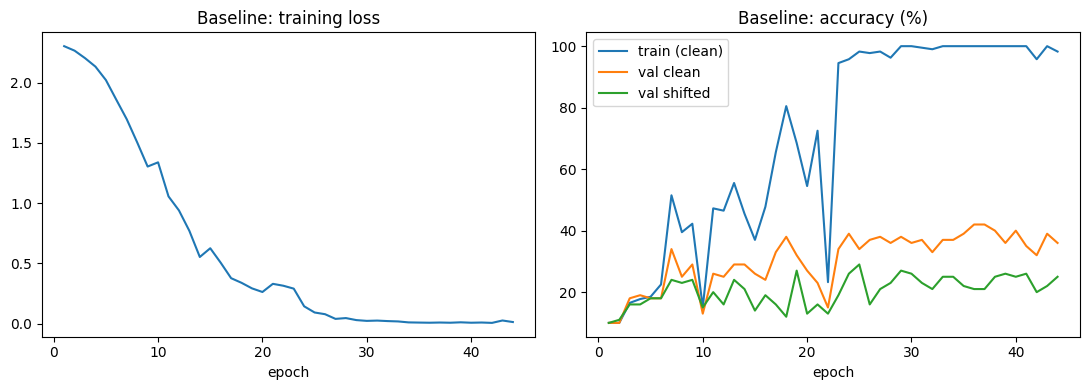

In [10]:
# 10. Part A results: baseline table and learning curves
b = rows["No augmentation"]
print("PART A (no augmentation, mean ± std over seeds)")
print(f"train {ms(b['train'])} | val {ms(b['val'])} | clean test {ms(b['clean'])} | shifted test {ms(b['shifted'])}")

h = hists0["No augmentation"]; ep = range(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h["loss"]); ax[0].set_title("Baseline: training loss"); ax[0].set_xlabel("epoch")
for k, lab in [("train", "train (clean)"), ("val_clean", "val clean"), ("val_shift", "val shifted")]:
    ax[1].plot(ep, h[k], label=lab)
ax[1].set_title("Baseline: accuracy (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/partA_learning_curves.png", dpi=150); plt.show()

In [11]:
# 11. Part D: ablation table
lines = ["| Configuration | Val Acc | Clean Test | Shifted Test |", "|---|---|---|---|"]
for name, r in rows.items():
    lines.append(f"| {name} | {ms(r['val'])} | {ms(r['clean'])} | {ms(r['shifted'])} |")
table = "\n".join(lines)
print(table)
open(f"{OUT}/ablation_table.md", "w").write(table + f"\n\nSelected hyperparameters: {BEST_HP}\n")

| Configuration | Val Acc | Clean Test | Shifted Test |
|---|---|---|---|
| No augmentation | 32.50 ± 2.00 | 35.79 ± 4.98 | 17.40 ± 1.63 |
| Geometric only | 38.83 ± 1.26 | 39.54 ± 4.27 | 23.18 ± 1.74 |
| Photometric only | 34.83 ± 2.57 | 38.22 ± 4.99 | 22.44 ± 1.77 |
| Geometric + photometric | 40.83 ± 4.19 | 40.45 ± 5.91 | 25.96 ± 3.34 |
| + Cutout / Random Erasing | 40.50 ± 2.00 | 42.07 ± 1.62 | 28.80 ± 1.79 |
| + Mixup/CutMix + label smoothing | 40.00 ± 2.00 | 36.61 ± 2.85 | 25.90 ± 1.93 |
| Final model | 42.00 ± 3.50 | 38.96 ± 0.19 | 26.59 ± 0.60 |


626

In [12]:
# 12. Which augmentation fixes which corruption (needed to explain Part D)
corr_sets = {op: corrupt(Xte, 77, ops=(op,), p_one=True) for op in ALL_OPS}   # each image gets ONE corruption
print(f"{'configuration (seed 0)':36s}" + "".join(f"{op:>8s}" for op in ALL_OPS))
per_corr = {}
for name, m in models0.items():
    a = {op: acc(m, corr_sets[op], yte) for op in ALL_OPS}
    per_corr[name] = a
    print(f"{name:36s}" + "".join(f"{a[op]:8.1f}" for op in ALL_OPS))

configuration (seed 0)                   rot      bc    blur   noise     occ  hidden
No augmentation                         29.9    32.9    23.2    37.0    20.5    31.4
Geometric only                          42.4    35.6    29.5    37.7    36.0    30.6
Photometric only                        34.5    38.2    36.3    38.2    24.4    33.7
Geometric + photometric                 44.0    42.3    44.0    43.5    33.8    32.9
+ Cutout / Random Erasing               43.2    41.3    42.2    42.4    37.2    32.3
+ Mixup/CutMix + label smoothing        37.9    35.7    38.2    36.1    32.9    25.9
Final model                             39.0    36.1    37.5    36.8    34.0    27.8


E1. per-class accuracy (%):
  airplane     34.9
  automobile   41.1
  bird         10.1
  cat          34.3
  deer         19.8
  dog           8.9
  frog         30.2
  horse        27.0
  ship         50.5
  truck        13.3
E2. most confused pairs (true -> predicted):
  dog -> cat: 38.4% of dog images
  airplane -> ship: 27.1% of airplane images
  truck -> automobile: 25.6% of truck images
  horse -> cat: 25.3% of horse images
  bird -> cat: 21.3% of bird images
  truck -> ship: 20.1% of truck images


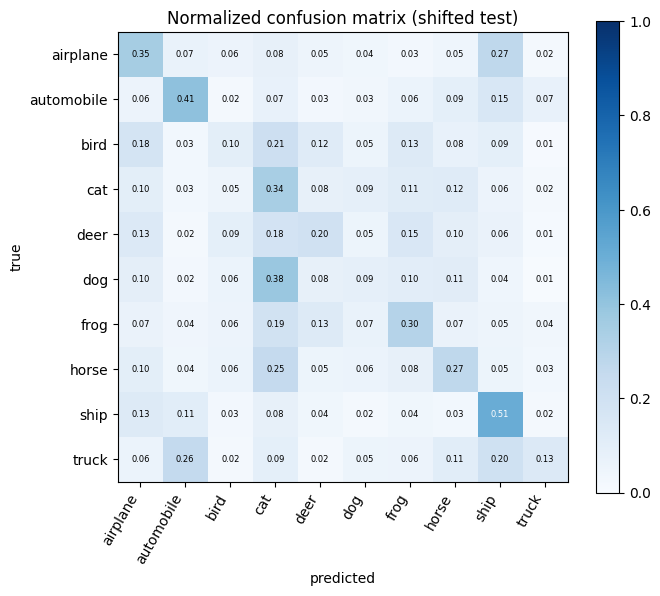

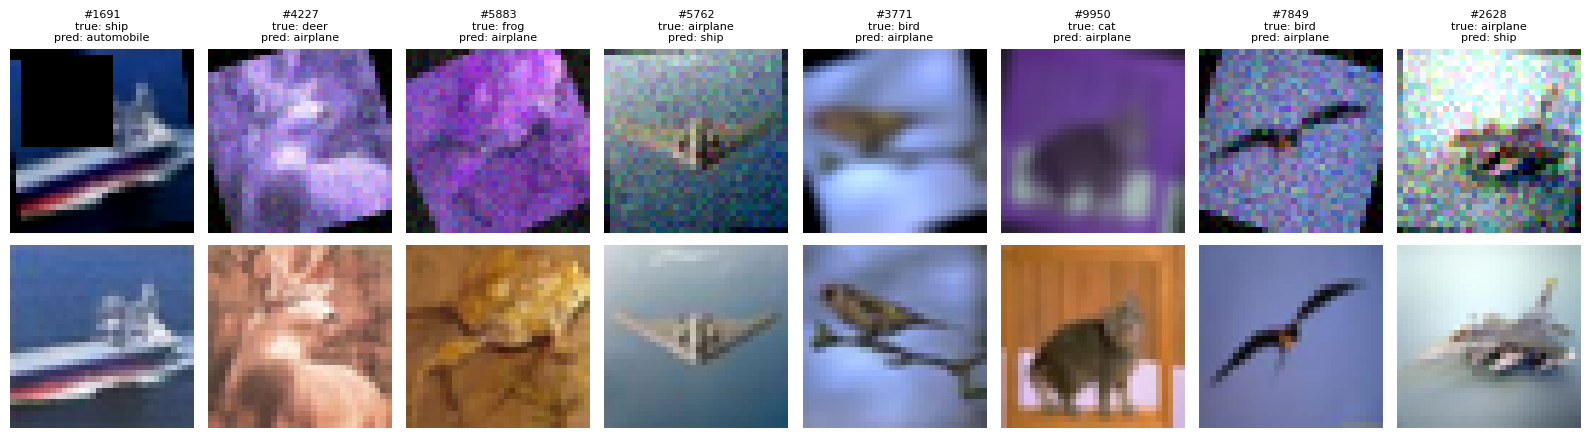

E4. hidden corruption ONLY applied to clean test (seed 0 models):
  No augmentation                      clean  39.2 | hidden-only  31.4
  Geometric only                       clean  43.0 | hidden-only  30.6
  Photometric only                     clean  39.7 | hidden-only  33.7
  Geometric + photometric              clean  44.7 | hidden-only  32.9
  + Cutout / Random Erasing            clean  43.8 | hidden-only  32.3
  + Mixup/CutMix + label smoothing     clean  38.0 | hidden-only  25.9
  Final model                          clean  39.0 | hidden-only  27.8


In [13]:
# 13. Part E: error analysis of the final model (seed 0) on the shifted test
fm = models0["Final model"]
prob = predict(fm, shifted_test); pred = prob.argmax(1)
cm = np.zeros((10, 10))
for t, p in zip(yte.numpy(), pred.numpy()): cm[t, p] += 1
cmn = cm / cm.sum(1, keepdims=True)

print("E1. per-class accuracy (%):")
for c, a in zip(CLASSES, cmn.diagonal() * 100): print(f"  {c:11s} {a:5.1f}")
off = sorted([(cmn[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j], reverse=True)
print("E2. most confused pairs (true -> predicted):")
for v, a, b_ in off[:6]: print(f"  {a} -> {b_}: {v * 100:.1f}% of {a} images")

fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Normalized confusion matrix (shifted test)")
plt.colorbar(im); plt.tight_layout(); plt.savefig(f"{OUT}/partE_confusion.png", dpi=150); plt.show()

# E3: 8 most confidently wrong images (shifted on top, clean original below)
wrong = (pred != yte).nonzero().flatten()
pick = wrong[prob[wrong, pred[wrong]].argsort(descending=True)[:8]]
fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
for k, i in enumerate(pick.tolist()):
    ax[0, k].imshow(shifted_test[i].permute(1, 2, 0)); ax[1, k].imshow(Xte[i].permute(1, 2, 0))
    ax[0, k].set_title(f"#{i}\ntrue: {CLASSES[yte[i]]}\npred: {CLASSES[pred[i]]}", fontsize=8)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/partE_misclassified.png", dpi=150); plt.show()

# E4: hidden corruption only
print("E4. hidden corruption ONLY applied to clean test (seed 0 models):")
for name, m in models0.items():
    print(f"  {name:36s} clean {acc(m, Xte, yte):5.1f} | hidden-only {per_corr[name]['hidden']:5.1f}")

In [14]:
# 14. Part F (bonus): test-time augmentation
def shift(x, dx, dy, pad=2):
    xp = F.pad(x, (pad,) * 4)
    return xp[:, :, pad - dy: pad - dy + 32, pad - dx: pad - dx + 32]

@torch.no_grad()
def tta_predict(model, X, bs=1000):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(dev)
        views = [x, x.flip(3)] + [shift(x, dx, dy) for dx, dy in [(2, 0), (-2, 0), (0, 2), (0, -2)]] \
                + [shift(x, 2, 2).flip(3), shift(x, -2, -2).flip(3)]            # 8 views
        out.append((sum(model(v).softmax(1) for v in views) / len(views)).cpu())
    return torch.cat(out)

def timed(fn):
    if dev == "cuda": torch.cuda.synchronize()
    t = time.time(); o = fn()
    if dev == "cuda": torch.cuda.synchronize()
    return o, time.time() - t

predict(fm, shifted_test[:1000])                       # warm-up
p0, t0 = timed(lambda: predict(fm, shifted_test))
p1, t1 = timed(lambda: tta_predict(fm, shifted_test))
a0 = (p0.argmax(1) == yte).float().mean().item() * 100
a1 = (p1.argmax(1) == yte).float().mean().item() * 100
print(f"without TTA: {a0:.2f}%  ({t0:.2f}s for 10,000 images)")
print(f"with 8-view TTA: {a1:.2f}%  ({t1:.2f}s)  -> change {a1 - a0:+.2f} points, cost x{t1 / t0:.1f}")

without TTA: 27.01%  (0.33s for 10,000 images)
with 8-view TTA: 26.79%  (2.52s)  -> change -0.22 points, cost x7.6
